# Feature Selection

> Shows feature elimination decisions (variance threshold, correlation pruning, leakage checks). Logs results in a table (results/feature_selection.csv).

In [124]:
import numpy as np
# Set numpy to print only 2 decimal digits for neatness
np.set_printoptions(precision=2, suppress=True)

import nibabel as nib
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from os import listdir
from os.path import isfile, join

## Grey and White Matter Selection

If we take the brain scan data, make a histogram of the values which corespond to the darkness of the pixel, and select the first two "bumps" in the histogram, we will be selecting the grey matter and white matter, respectively. Examples of this can be found in `../tests/test_scans.ipynb`.

We need a way to automate this process since this cannot be done by hand across over 1000 images. 

In [134]:
mypath = "../data/MRI/Axial"
sigma = 1

file = [f for f in listdir(mypath) if isfile(join(mypath, f))]
mins_grey = []
maxs_grey = []
mins_white = []
maxs_white = []
for f in file:
    brain_vol = nib.load(join(mypath, f))
    brain_vol_data = brain_vol.get_fdata()

    filt = ndi.gaussian_filter(brain_vol_data, sigma=sigma)
    filt_hist = ndi.histogram(filt, min=0, max=np.max(filt), bins=50)

    gr = np.gradient(filt_hist)
    idx1, _ = find_peaks(gr, distance=1)
    idx2, _ = find_peaks(-gr, distance=1)
    idx = np.sort(np.array([idx1[:4], idx2[:4]]).flatten())

    mins_grey.append(idx[1])
    mins_white.append(idx[2])
    maxs_grey.append(idx[2]-1)
    maxs_white.append(idx[4])

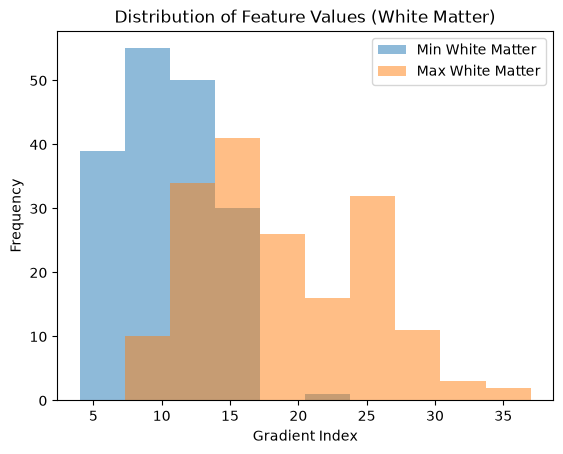

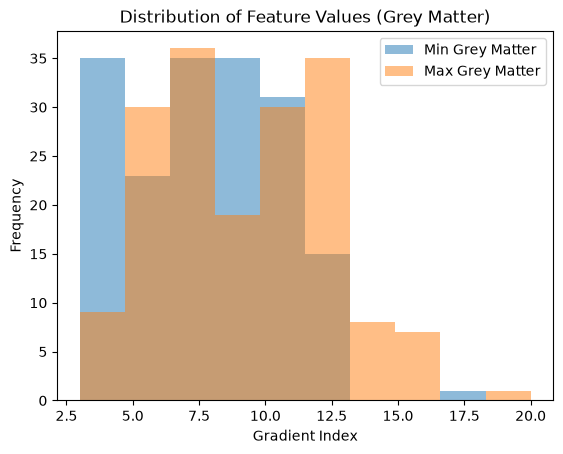

In [148]:
plt.hist(mins_white, alpha=0.5, range=(min(mins_white), max(maxs_white)), label='Min White Matter')
plt.hist(maxs_white, alpha=0.5, range=(min(mins_white), max(maxs_white)), label='Max White Matter')
plt.xlabel('Gradient Index')
plt.ylabel('Frequency')
plt.title('Distribution of Feature Values (White Matter)')
plt.legend()
plt.show()

plt.hist(mins_grey, alpha=0.5, range=(min(mins_grey), max(maxs_grey)), label='Min Grey Matter')
plt.hist(maxs_grey, alpha=0.5, range=(min(mins_grey), max(maxs_grey)), label='Max Grey Matter')
plt.xlabel('Gradient Index')
plt.ylabel('Frequency')
plt.title('Distribution of Feature Values (Grey Matter)')
plt.legend()
plt.show()

In [136]:
mypath = "../data/MRI/Axial"
sigma = 1

file = [f for f in listdir(mypath) if isfile(join(mypath, f))]
idx = []
for f in file:
    brain_vol = nib.load(join(mypath, f))
    brain_vol_data = brain_vol.get_fdata()

    filt = ndi.gaussian_filter(brain_vol_data, sigma=sigma)
    filt_hist = ndi.histogram(filt, min=0, max=np.max(filt), bins=50)

    gr = np.gradient(filt_hist)
    idx1, _ = find_peaks(gr, distance=1)
    idx2, _ = find_peaks(-gr, distance=1)
    idx.append(np.sort(np.array([idx1[:4], idx2[:4]]).flatten()))

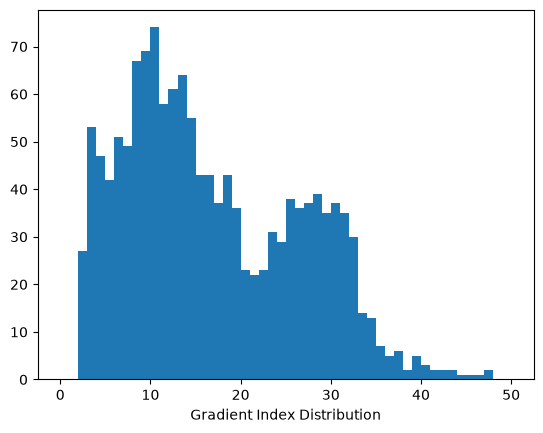

In [147]:
plt.hist(np.array(idx).flatten(), bins=50, range=(0,50))
plt.xlabel("Gradient Index Distribution")
plt.show()